# Independent comparative geometry review

Compare multiple embedded scenes and preserve a readable static reference without changing physical model inputs.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

Each call to `.widget()` creates a separate model and view state. Place two handles in an `HBox` to compare cases while keeping the original geometry immutable. The model IDs and selection properties make their independence inspectable from Python.

The partition and viewer figures explain two different comparisons: geometric detail can change the number of resolved surfaces, while a cutaway changes only what is displayed. Neither an opacity change nor camera motion changes energy inputs. This notebook changes roof and zoning together for visual teaching; a causal energy experiment should vary them separately.

Reference: [The same forms under different thermal partitions](../../docs/figures/geometry-zoning.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Display independent widgets

Each widget has its own controls and selection state. Changing one view must not change another or mutate the underlying immutable GeometrySpec.

### Read the code and output

The left and right widget handles are independent, even though the right geometry was derived from the left through a validated update. You can orbit or select one without using the other as a camera controller. Their static references also preserve the comparison when the notebook is read without active widgets.

Reference: [Existing viewer controls and target/context separation](../../docs/figures/viewer-controls.png). This linked documentation illustration is separate from the outputs computed below.

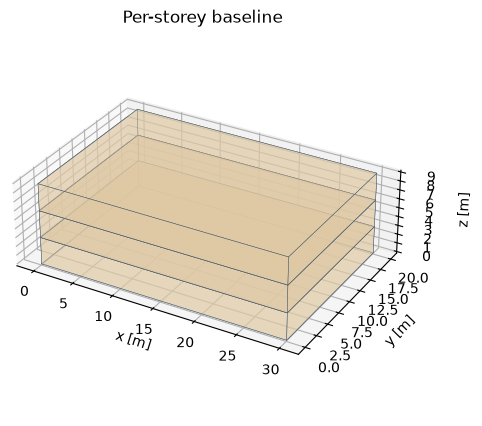

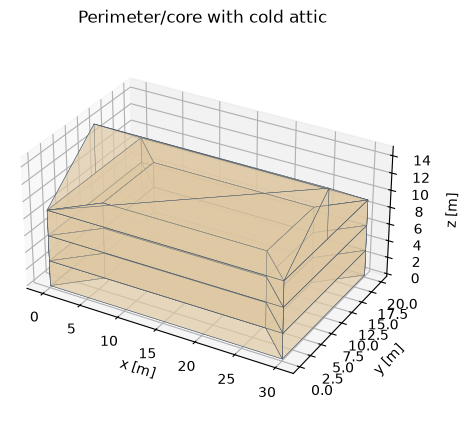

In [2]:
from ipywidgets import HBox,Layout
from epsm_core import preview_geometry
left=geometry(); right=left.updated(zoning=ZoningSpec(mode="perimeter_core"),roof=RoofSpec(shape="gable"))
w1=left.widget(height=500); w2=right.widget(height=500)
display(HBox([w1,w2],layout=Layout(width="100%")))
assert w1.model_id!=w2.model_id
preview(left,"Per-storey baseline",interactive=False)
preview(right,"Perimeter/core with cold attic",interactive=False)

## Read scene complexity

The comparison changes two controls for visual teaching. For energy attribution, change them separately using matched simulations.

### Read the code and output

Object count measures scene complexity, not area, mass or accuracy. Read it alongside the roof and zoning choices to understand why it changes. The selection table is a snapshot: rerun it after interacting if you want the current chosen surface names.

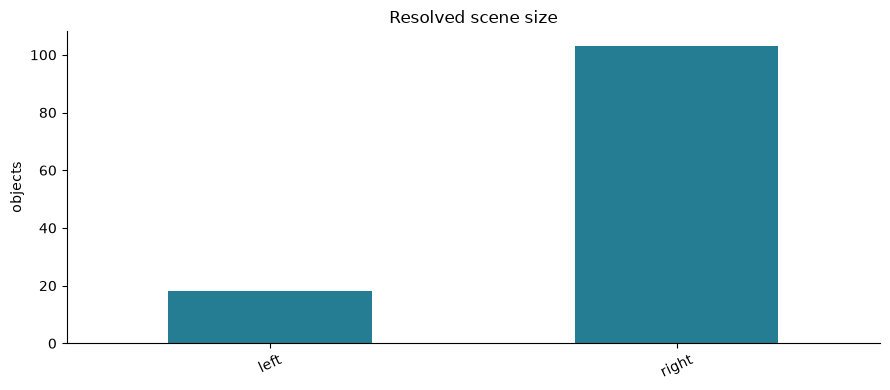

,field,value
0,left_selection,
1,right_selection,


In [3]:
bars({"left":len(w1.scene["objects"]),"right":len(w2.scene["objects"])},"objects","Resolved scene size")
table({"left_selection":w1.selected_surface,"right_selection":w2.selected_surface})
assert left.zoning.mode=="per_storey"

## Exercise public preview aliases

GeometrySpec.view, BuildingSpec.view and preview_geometry retain standalone server behaviour. Notebook widgets are the inline interface; the following handles are closed promptly after HTTP checks.

### Read the code and output

`GeometrySpec.view` and `preview_geometry` still provide the standalone browser-server interface. These short checks close their handles promptly. Use the embedded widget for inline interaction and keep the server handle open only when you intentionally need its URL in a standalone workflow.

In [4]:
from urllib.request import urlopen
with left.view(OUT/"geometry",launch_browser=False) as handle:
    assert urlopen(handle.url).status==200
with preview_geometry(right,OUT/"preview",launch_browser=False) as handle:
    assert urlopen(handle.url).status==200

## Interpretation and next experiment

Keep preview complexity bounded when inspecting many buildings. A representative gallery is more useful than loading a whole national stock into one WebGL scene.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.